In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# List of color ranges in HSV (this needs to be customized based on your specific colors)
color_ranges = [
    {"color": "red", "lower": (0, 100, 100), "upper": (10, 255, 255)},
    {"color": "green", "lower": (40, 100, 100), "upper": (70, 255, 255)},
    {"color": "blue", "lower": (100, 100, 100), "upper": (130, 255, 255)},
    {"color": "yellow", "lower": (20, 100, 100), "upper": (30, 255, 255)},
    {"color": "orange", "lower": (10, 100, 100), "upper": (20, 255, 255)},
    {"color": "purple", "lower": (130, 100, 100), "upper": (160, 255, 255)},
    {"color": "pink", "lower": (160, 100, 100), "upper": (180, 255, 255)},
    {"color": "cyan", "lower": (80, 100, 100), "upper": (100, 255, 255)},
    # {"color": "brown", "lower": (0, 100, 100), "upper": (20, 255, 255)},
    {"color": "black", "lower": (0, 0, 0), "upper": (180, 255, 30)},
    # {"color": "white", "lower": (0, 0, 200), "upper": (180, 20, 255)},
    # Add more color ranges as needed
]

names = ['rectangle', 'circle', 'triangle']

im_size = 64

In [33]:
image_path = "./data/a.png"
img = cv2.imread(image_path)

In [34]:
# Visualize the image
def show_image(img):
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
    
def show_image_3(im_list):
    fig, axs = plt.subplots(1, 3, figsize=(10, 10))
    for i in range(3):
        axs[i].imshow(cv2.cvtColor(im_list[i], cv2.COLOR_BGR2RGB))
        axs[i].axis('off')
    plt.show()

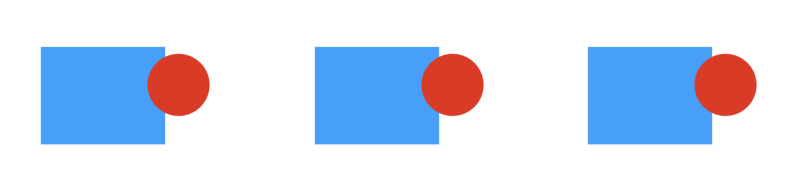

In [35]:
show_image_3([img, img, img])

In [36]:
# Convert the image to HSV
hsv = cv2.cvtColor(img.copy(), cv2.COLOR_BGR2HSV)

shape_count = 0
shapes = []
shape_imgs = []

for color_range in color_ranges:
    # Create a mask for the current color
    mask = cv2.inRange(hsv, color_range["lower"], color_range["upper"])

    # Find contours in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for contour in contours:
        # Create a bounding box around each contour
        if cv2.contourArea(contour) < 100:
            continue

        # Create a blank binary image
        shape_img = np.zeros_like(img[:, :, 0])

        # Draw the contour on the binary image
        cv2.drawContours(shape_img, [contour], -1, (255), thickness=cv2.FILLED)

        # Crop the binary image to the bounding box
        x, y, w, h = cv2.boundingRect(contour)
        shape_img = shape_img[y:y + h, x:x + w]

        # Save the extracted shape
        shape_count += 1
        shape_filename = f'outputs/shape_{shape_count}_{color_range["color"]}.png'
        cv2.imwrite(shape_filename, shape_img)
        shapes.append(shape_img)
        shape_imgs.append(img[y:y + h, x:x + w])
        print(f'Saved {shape_filename}, w: {w}, h: {h}')

Saved outputs/shape_1_red.png, w: 229, h: 229
Saved outputs/shape_2_blue.png, w: 459, h: 360


In [37]:
# show_image_3(shape_imgs)
for shape in shapes:
    print(shape.shape)

(229, 229)
(360, 459)


164748.26034690233 165240 0.4992549134133125 0.5007450865866876


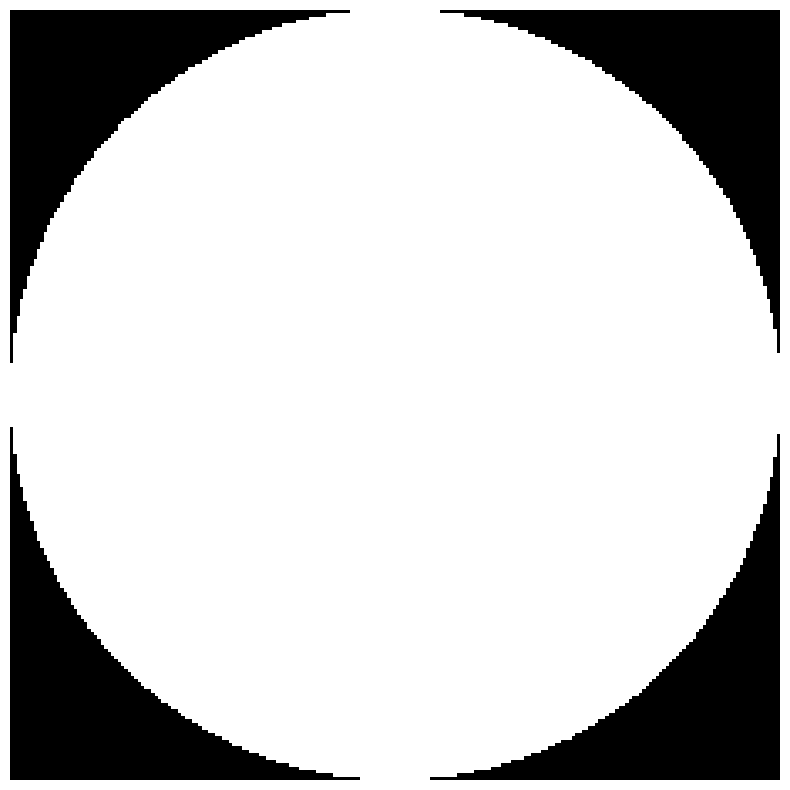

In [44]:
s1 = 229*229*np.pi
s2 = 360*459
print(s1, s2, s1/(s1+s2), s2/(s1+s2))
show_image(shapes[0])